# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Anak Agung Gede Wisnu Mahadhiva
- **Email:** gungwisnuuu@gmail.com
- **ID Dicoding:** gungwisnu

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana perbandingan rata-rata penyewaan sepeda harian berdasarkan kondisi cuaca (*weathersit*) dan musim (*season*) selama periode operasional Januari 2011 hingga Desember 2012, serta seberapa besar persentase penurunan jumlah sewa saat cuaca memburuk?
- **Pertanyaan 2:** Pada jam berapa saja terjadi puncak penyewaan sepeda oleh pelanggan terdaftar (*registered*) dibandingkan pengguna lepas (*casual*) saat hari kerja (*workingday*) dan hari libur sepanjang tahun 2012?

## Import Semua Packages/Library yang Digunakan

In [35]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

## Data Wrangling

### Gathering Data

#### Load df_day dan df_hour

In [36]:
df_day = pd.read_csv("data/day.csv")

df_day.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [37]:
df_hour = pd.read_csv("data/hour.csv")

df_hour.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- Data berhasil dibaca dari folder `data/` menjadi dua tabel, yaitu `df_day` yang berisi rekap harian (731 baris, 16 kolom) dan `df_hour` yang menyimpan rekap per jam (17.379 baris, 17 kolom).
- Kolom pada kedua tabel pada dasarnya sama, hanya saja di `df_hour` terdapat kolom tambahan `hr` untuk menampung informasi jam (0 sampai 23).

### Assessing Data

#### Identifying tipe data tanggal, kode kategori, dan anomali nilai kelembapan problem

In [38]:
df_day.info()
print("\nCek missing value df_day:", df_day.isna().sum().sum())
print("Cek duplikat df_day:", df_day.duplicated().sum())
print("Cek missing value df_hour:", df_hour.isna().sum().sum())
print("Cek duplikat df_hour:", df_hour.duplicated().sum())

df_day.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

Cek missing value df_day: 0
Cek duplikat df_day: 0
Cek missing value df_hour: 0
Cek duplikat

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


**Steps to Take:**
- Mengonversi kolom `dteday` pada kedua tabel dari tipe `object` ke `datetime` agar bisa diolah berdasarkan waktu.
- Mengganti angka kode pada kolom kategori (`season`, `yr`, `workingday`, `weathersit`) menjadi teks keterangan langsung, mengembalikan nilai `temp` dan `hum` ke skala aslinya, serta memperbaiki nilai `hum` yang tercatat 0 pada `df_day` dan `df_hour` menggunakan nilai median.

**Insight:** (Opsional)
- Dari hasil pengecekan `isna()` dan `duplicated()`, baik `df_day` maupun `df_hour` bersih dari data kosong dan baris ganda.
- Ada 3 hal yang perlu dibereskan di tahap cleaning: tipe data `dteday` masih string (`object`), beberapa kolom kategori masih berbentuk angka kode (1-4) beserta angka suhu/kelembapan yang masih dibagi nilai maksimumnya, serta terdapat nilai minimum `hum` = 0 (kelembapan udara 0% tidak wajar terjadi di kondisi normal).

### Cleaning Data

#### Fixing tipe data dteday, mapping label kategori, dan imputasi outlier kelembapan problem

In [39]:
df_day["dteday"] = pd.to_datetime(df_day["dteday"])
df_hour["dteday"] = pd.to_datetime(df_hour["dteday"])

label_musim = {1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"}
label_cuaca = {1: "Cerah/Berawan", 2: "Berkabut/Mendung", 3: "Hujan Ringan/Salju", 4: "Cuaca Buruk"}
label_hari = {0: "Libur/Akhir Pekan", 1: "Hari Kerja"}

df_day["season"] = df_day["season"].map(label_musim)
df_day["yr"] = df_day["yr"].map({0: 2011, 1: 2012})
df_day["workingday"] = df_day["workingday"].map(label_hari)
df_day["weathersit"] = df_day["weathersit"].map(label_cuaca)
df_day["temp"] = df_day["temp"] * 41
df_day["hum"] = df_day["hum"] * 100
df_day["windspeed"] = df_day["windspeed"] * 67

df_hour["season"] = df_hour["season"].map(label_musim)
df_hour["yr"] = df_hour["yr"].map({0: 2011, 1: 2012})
df_hour["workingday"] = df_hour["workingday"].map(label_hari)
df_hour["weathersit"] = df_hour["weathersit"].map(label_cuaca)
df_hour["temp"] = df_hour["temp"] * 41
df_hour["hum"] = df_hour["hum"] * 100
df_hour["windspeed"] = df_hour["windspeed"] * 67

nilai_tengah_hum = df_day[df_day["hum"] > 0]["hum"].median()
df_day.loc[df_day["hum"] == 0, "hum"] = nilai_tengah_hum
df_hour.loc[df_hour["hum"] == 0, "hum"] = nilai_tengah_hum

df_day[["dteday", "yr", "season", "workingday", "weathersit", "temp", "hum", "cnt"]].head()

,dteday,yr,season,workingday,weathersit,temp,hum,cnt
0,2011-01-01,2011,Spring,Libur/Akhir Pekan,Berkabut/Mendung,14.110847,80.5833,985
1,2011-01-02,2011,Spring,Libur/Akhir Pekan,Berkabut/Mendung,14.902598,69.6087,801
2,2011-01-03,2011,Spring,Hari Kerja,Cerah/Berawan,8.050924,43.7273,1349
3,2011-01-04,2011,Spring,Hari Kerja,Cerah/Berawan,8.200000,59.0435,1562
4,2011-01-05,2011,Spring,Hari Kerja,Cerah/Berawan,9.305237,43.6957,1600


**Insight:** (Opsional)
- Kolom tanggal `dteday` sudah berubah menjadi `datetime64[ns]` dan angka-angka kode pada musim, tahun, status hari kerja, serta cuaca sudah diganti dengan nama kategorinya.
- Nilai suhu (`temp`) dan kelembapan (`hum`) sudah dikembalikan ke satuan Celcius dan persen, lalu baris data yang tadinya memiliki kelembapan 0% sudah diganti dengan nilai median (62,67%).

## Exploratory Data Analysis (EDA)

### Explore rata-rata sewa berdasarkan cuaca, musim, dan jam operasional

In [40]:
rekap_cuaca = df_day.groupby("weathersit").agg(
    jumlah_hari=("cnt", "count"),
    total_sewa=("cnt", "sum"),
    rata_rata_harian=("cnt", "mean")
).sort_values(by="rata_rata_harian", ascending=False).reset_index()
print("Rekap penyewaan berdasarkan kondisi cuaca:")
print(rekap_cuaca)

rekap_musim_tahun = df_day.groupby(["yr", "season"]).agg(
    total_sewa=("cnt", "sum"),
    rata_rata_harian=("cnt", "mean")
).reset_index()
print("\nRekap penyewaan per musim (2011 vs 2012):")
print(rekap_musim_tahun)

jam_2012 = df_hour[df_hour["yr"] == 2012].groupby(["workingday", "hr"])[["registered", "casual", "cnt"]].mean().reset_index()
print("\nJam paling ramai saat Hari Kerja (2012):")
print(jam_2012[jam_2012["workingday"] == "Hari Kerja"].sort_values(by="cnt", ascending=False).head(3))
print("\nJam paling ramai saat Libur/Akhir Pekan (2012):")
print(jam_2012[jam_2012["workingday"] == "Libur/Akhir Pekan"].sort_values(by="cnt", ascending=False).head(3))

Rekap penyewaan berdasarkan kondisi cuaca:
           weathersit  jumlah_hari  total_sewa  rata_rata_harian
0       Cerah/Berawan          463     2257952       4876.786177
1    Berkabut/Mendung          247      996858       4035.862348
2  Hujan Ringan/Salju           21       37869       1803.285714

Rekap penyewaan per musim (2011 vs 2012):
     yr  season  total_sewa  rata_rata_harian
0  2011    Fall      419650       4464.361702
1  2011  Spring      150000       1666.666667
2  2011  Summer      347316       3775.173913
3  2011  Winter      326137       3664.460674
4  2012    Fall      641479       6824.244681
5  2012  Spring      321348       3531.296703
6  2012  Summer      571273       6209.489130
7  2012  Winter      515476       5791.865169

Jam paling ramai saat Hari Kerja (2012):
    workingday  hr  registered     casual         cnt
17  Hari Kerja  17  586.413655  69.775100  656.188755
18  Hari Kerja  18  556.096386  60.903614  617.000000
8   Hari Kerja   8  580.201613  24.3

**Insight:** (Opsional)
- Kondisi cuaca sangat memengaruhi jumlah peminjam: saat cuaca Cerah/Berawan rata-rata sewa mencapai 4.877 unit/hari, turun ke 4.035 unit/hari saat Berkabut/Mendung (-17,2%), dan anjlok ke 1.803 unit/hari saat Hujan Ringan/Salju (-63,0% dibanding cuaca cerah). Dari sisi musim, rata-rata tertinggi ada di musim Fall dan terendah di musim Spring baik di tahun 2011 maupun 2012.
- Untuk data per jam di tahun 2012, hari kerja mencapai titik tertinggi di jam 17:00 (rata-rata 656 sewa/jam) dan jam 08:00 pagi (604 sewa/jam) yang hampir seluruhnya berasal dari member `registered`. Saat akhir pekan/hari libur, jam ramai bergeser ke tengah hari sekitar pukul 12:00 sampai 14:00 (puncaknya jam 13:00 dengan 459 sewa/jam).

## Visualization & Explanatory Analysis

### Pertanyaan 1:

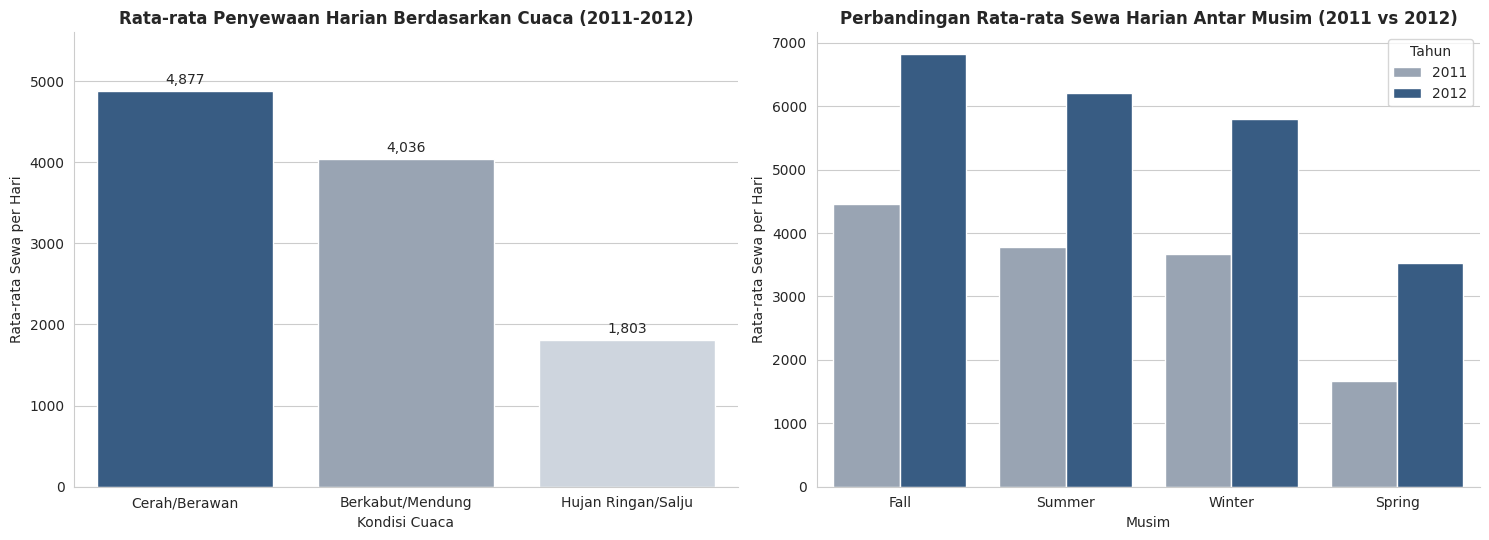

In [41]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))

urut_cuaca = rekap_cuaca["weathersit"].tolist()
warna_cuaca = ["#2b5c8f", "#94a3b8", "#cbd5e1"]
sns.barplot(
    data=rekap_cuaca, x="weathersit", y="rata_rata_harian",
    order=urut_cuaca, palette=warna_cuaca, hue="weathersit", legend=False, ax=ax[0]
)
ax[0].set_title("Rata-rata Penyewaan Harian Berdasarkan Cuaca (2011-2012)", fontsize=12, fontweight="bold")
ax[0].set_xlabel("Kondisi Cuaca")
ax[0].set_ylabel("Rata-rata Sewa per Hari")
for idx, val in enumerate(rekap_cuaca["rata_rata_harian"]):
    ax[0].text(idx, val + 90, f"{val:,.0f}", ha="center", fontsize=10)
ax[0].set_ylim(0, 5600)

urut_musim = ["Fall", "Summer", "Winter", "Spring"]
sns.barplot(
    data=rekap_musim_tahun, x="season", y="rata_rata_harian",
    hue="yr", order=urut_musim, palette=["#94a3b8", "#2b5c8f"], ax=ax[1]
)
ax[1].set_title("Perbandingan Rata-rata Sewa Harian Antar Musim (2011 vs 2012)", fontsize=12, fontweight="bold")
ax[1].set_xlabel("Musim")
ax[1].set_ylabel("Rata-rata Sewa per Hari")
ax[1].legend(title="Tahun")

sns.despine()
plt.tight_layout()
plt.show()

### Pertanyaan 2:

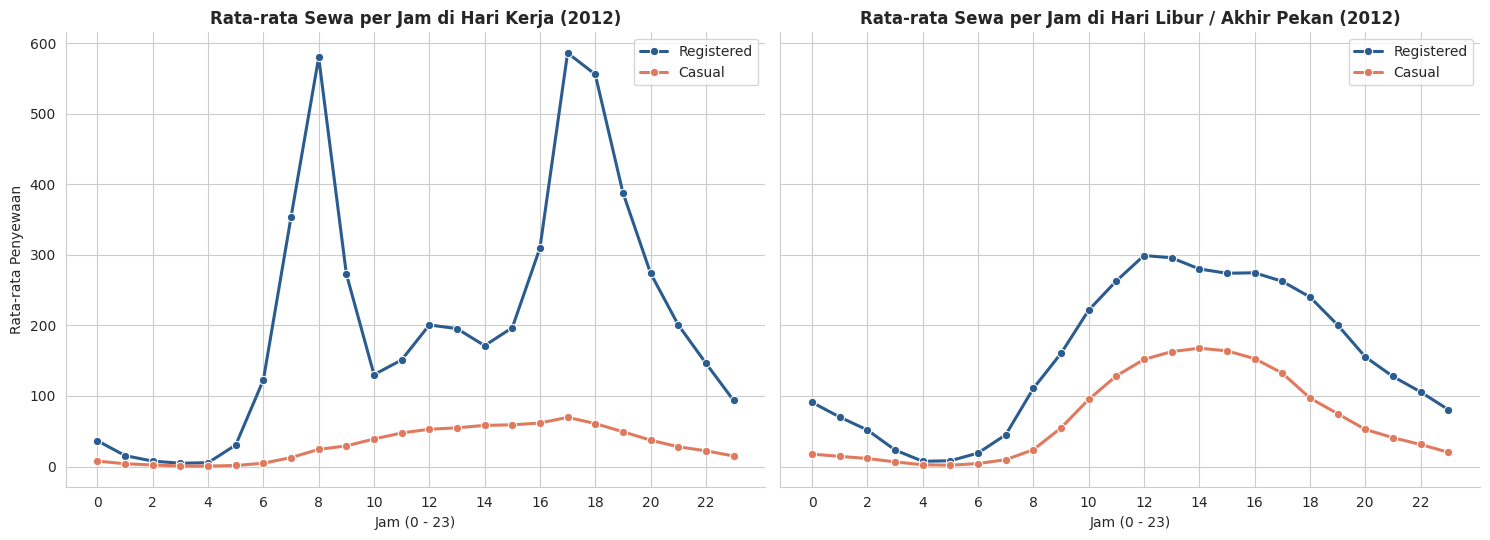

In [42]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)

df_kerja = jam_2012[jam_2012["workingday"] == "Hari Kerja"]
sns.lineplot(data=df_kerja, x="hr", y="registered", label="Registered", color="#2b5c8f", marker="o", linewidth=2.2, ax=ax[0])
sns.lineplot(data=df_kerja, x="hr", y="casual", label="Casual", color="#e07a5f", marker="o", linewidth=2.2, ax=ax[0])
ax[0].set_title("Rata-rata Sewa per Jam di Hari Kerja (2012)", fontsize=12, fontweight="bold")
ax[0].set_xlabel("Jam (0 - 23)")
ax[0].set_ylabel("Rata-rata Penyewaan")
ax[0].set_xticks(range(0, 24, 2))
ax[0].legend()

df_libur = jam_2012[jam_2012["workingday"] == "Libur/Akhir Pekan"]
sns.lineplot(data=df_libur, x="hr", y="registered", label="Registered", color="#2b5c8f", marker="o", linewidth=2.2, ax=ax[1])
sns.lineplot(data=df_libur, x="hr", y="casual", label="Casual", color="#e07a5f", marker="o", linewidth=2.2, ax=ax[1])
ax[1].set_title("Rata-rata Sewa per Jam di Hari Libur / Akhir Pekan (2012)", fontsize=12, fontweight="bold")
ax[1].set_xlabel("Jam (0 - 23)")
ax[1].set_xticks(range(0, 24, 2))
ax[1].legend()

sns.despine()
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Dari grafik pertama terlihat jelas bahwa cuaca hujan ringan/salju memangkas minat bersepeda hingga lebih dari separuh dibandingkan saat cuaca cerah. Selain itu, terjadi lonjakan rata-rata sewa harian yang cukup besar dari tahun 2011 ke 2012 di keempat musim, terutama pada musim Fall (mencapai lebih dari 6.600 sewa/hari di tahun 2012).
- Grafik kedua menunjukkan perbedaan kebiasaan pengguna di tahun 2012: saat hari kerja, penyewaan memuncak di jam berangkat (08:00) dan pulang kantor (17:00-18:00) oleh pelanggan `registered`. Sebaliknya saat hari libur, grafik naik perlahan sejak pagi dan ramai di jam 12:00-15:00 siang dengan jumlah penyewa `casual` yang naik lebih dari dua kali lipat dibanding hari biasa.

## Analisis Lanjutan (Opsional)

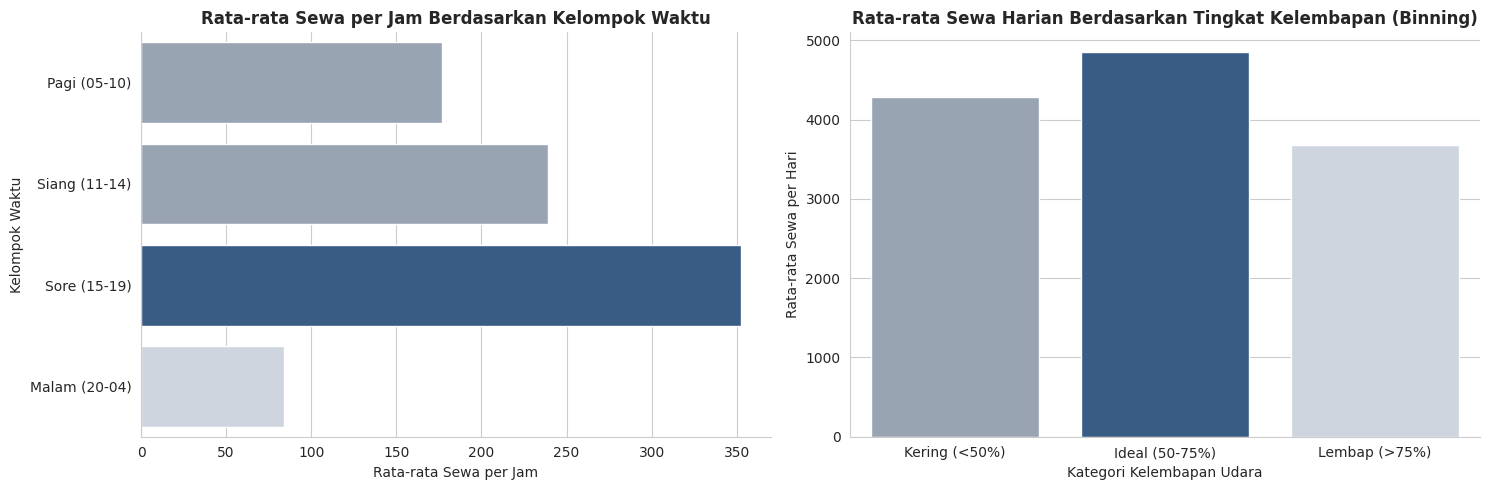

In [43]:
def kelompok_jam(jam):
    if 5 <= jam <= 10:
        return "Pagi (05-10)"
    elif 11 <= jam <= 14:
        return "Siang (11-14)"
    elif 15 <= jam <= 19:
        return "Sore (15-19)"
    else:
        return "Malam (20-04)"

df_hour["waktu_sewa"] = df_hour["hr"].apply(kelompok_jam)

df_day["hum_group"] = pd.cut(
    df_day["hum"],
    bins=[0, 50, 75, 100],
    labels=["Kering (<50%)", "Ideal (50-75%)", "Lembap (>75%)"]
)

rekap_waktu = df_hour.groupby("waktu_sewa")["cnt"].mean().reindex(
    ["Pagi (05-10)", "Siang (11-14)", "Sore (15-19)", "Malam (20-04)"]
).reset_index()

rekap_hum = df_day.groupby("hum_group", observed=False)["cnt"].mean().reset_index()

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

warna_waktu = ["#94a3b8", "#94a3b8", "#2b5c8f", "#cbd5e1"]
sns.barplot(data=rekap_waktu, x="cnt", y="waktu_sewa", palette=warna_waktu, hue="waktu_sewa", legend=False, ax=ax[0])
ax[0].set_title("Rata-rata Sewa per Jam Berdasarkan Kelompok Waktu", fontsize=12, fontweight="bold")
ax[0].set_xlabel("Rata-rata Sewa per Jam")
ax[0].set_ylabel("Kelompok Waktu")

warna_hum = ["#94a3b8", "#2b5c8f", "#cbd5e1"]
sns.barplot(data=rekap_hum, x="hum_group", y="cnt", palette=warna_hum, hue="hum_group", legend=False, ax=ax[1])
ax[1].set_title("Rata-rata Sewa Harian Berdasarkan Tingkat Kelembapan (Binning)", fontsize=12, fontweight="bold")
ax[1].set_xlabel("Kategori Kelembapan Udara")
ax[1].set_ylabel("Rata-rata Sewa per Hari")

sns.despine()
plt.tight_layout()
plt.show()

os.makedirs("dashboard", exist_ok=True)
df_day.to_csv("dashboard/main_data.csv", index=False)

**Insight:** (Opsional)
- Analisis lanjutan dilakukan dengan metode *manual grouping* pada jam sewa dan *binning* (`pd.cut`) pada tingkat kelembapan udara (`hum`) untuk melihat kondisi waktu serta kenyamanan udara yang paling disukai penyewa.
- Kelompok waktu Sore (15:00-19:00) menjadi sesi paling padat dengan rata-rata di atas 350 sewa/jam, disusul sesi Siang dan Pagi. Dari sisi kelembapan udara, penyewaan paling tinggi terjadi saat kelembapan berada di kategori Ideal (50-75%), sedangkan saat udara terlalu lembap (>75%) rata-rata penyewaan harian turun cukup jauh.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Kondisi cuaca dan musim terbukti berdampak besar pada tingkat penyewaan sepeda selama 2011–2012. Rata-rata penyewaan tertinggi terjadi saat cuaca Cerah/Berawan (4.877 unit/hari) dan pada musim Fall (5.644 unit/hari), sedangkan cuaca Hujan Ringan/Salju menyebabkan rata-rata penyewaan turun hingga 63% menjadi hanya 1.803 unit/hari, dengan musim paling sepi terjadi pada musim Spring (2.604 unit/hari).
- **Conclusion pertanyaan 2:** Pada tahun 2012, pola jam penyewaan terbagi jelas menurut jenis hari. Di hari kerja, puncak sewa terjadi pada jam 08:00 pagi (604 sewa/jam) dan 17:00 sore (656 sewa/jam) yang didominasi oleh pelanggan `registered`. Sebaliknya di hari libur, puncak keramaian terjadi di siang hari pukul 12:00–14:00 (tertinggi jam 13:00 sebanyak 459 sewa/jam) dengan kontribusi pengguna `casual` yang meningkat tajam hingga 168 sewa/jam.

**Rekomendasi Action Item:**
- Menjadwalkan pengecekan dan perbaikan rutin sepeda pada musim Spring atau saat prakiraan cuaca menunjukkan hujan/kelembapan tinggi (>75%) agar tidak mengganggu ketersediaan unit di musim ramai (Summer dan Fall).
- Memprioritaskan penempatan stok sepeda di area stasiun komuter/perkantoran sebelum jam 07:30 pagi dan 16:30 sore saat hari kerja, serta memberikan promo paket sewa akhir pekan di jam 11:00–15:00 untuk menarik pengguna `casual` agar mendaftar menjadi member `registered`.